In [1]:
!pip install qiskit qiskit-aer
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 82.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 111.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 77.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [2]:
import math
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

warnings.filterwarnings("ignore", category=DeprecationWarning)

# ---- global experiment settings ---------------------------------------
SEED  = 2026          # fixed seed: reproducible sampling and transpilation
SHOTS = 4096          # measurement shots per Aer run
SIM   = AerSimulator()
SAVE_FIGURES = False  # set True to also write every figure to results/figures/report/

# ---- plotting style ----------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.3,
})
C_CLASSICAL, C_GROVER = "#d62728", "#1f77b4"
C_SUCCESS, C_QUBITS, C_DEPTH, C_GATES = "#2ca02c", "#9467bd", "#ff7f0e", "#17becf"

# ---- locate the project root (for the dataset and the saved results) ---
def find_project_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "dataset.csv").exists():
            return p
    return None

ROOT = find_project_root()
FIG_DIR = (ROOT / "results" / "figures" / "report") if ROOT else None

def finish(fig, name, rect=None):
    """Show a figure and optionally save it."""
    fig.tight_layout(rect=rect) if rect else fig.tight_layout()
    if SAVE_FIGURES and FIG_DIR is not None:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / name)
    plt.show()

print(f"Python  : {'.'.join(map(str, __import__('sys').version_info[:3]))}")
print(f"Qiskit  : {qiskit.__version__}")
print(f"Aer     : {qiskit_aer.__version__}")
print(f"Seed    : {SEED}   Shots per run: {SHOTS}")
print(f"Project root: {ROOT}")

Python  : 3.13.16
Qiskit  : 2.6.1
Aer     : 0.18.0
Seed    : 2026   Shots per run: 4096
Project root: None


## Classical search and its query count

The classical baseline is a linear scan. Each loop iteration is **one query** (one evaluation of $f(x)=[x=w]$), and the function returns the number of queries it used.

In [3]:
def linear_search(search_space, target):
    """Classical linear search.

    Returns (index, queries): the index of `target` (-1 if absent) and the
    number of queries (comparisons) used.
    """
    queries = 0
    for i, element in enumerate(search_space):
        queries += 1                      # one query = one evaluation of f(x)
        if element == target:
            return i, queries
    return -1, queries


# Exhaustive evaluation: put the target at EVERY position and count queries.
rows = []
for N in (4, 8, 16, 32):
    space = list(range(N))
    q = [linear_search(space, t)[1] for t in range(N)]     # one run per possible target
    _, q_absent = linear_search(space, -1)                 # target not present
    rows.append({
        "N": N,
        "best case": min(q),
        "worst case": max(q),
        "average (measured)": float(np.mean(q)),
        "average (theory, (N+1)/2)": (N + 1) / 2,
        "target absent": q_absent,
    })

classical_table = pd.DataFrame(rows).set_index("N")
display(classical_table)

,best case,worst case,average (measured),"average (theory, (N+1)/2)",target absent
N,,,,,
4,1,4,2.5,2.5,4
8,1,8,4.5,4.5,8
16,1,16,8.5,8.5,16
32,1,32,16.5,16.5,32


**Result.** The measured query counts match theory exactly: best case $1$, worst case $N$ (target in the last position, or absent), and average $(N+1)/2$. The cost grows linearly with $N$, and no classical algorithm can do better on an unstructured space without extra information. This is the baseline Grover's algorithm is measured against.

## Analytical treatment of the small-qubit version (N = 4, two qubits)

This section works Grover's algorithm out **by hand and in full for the smallest non-trivial case: $n=2$ qubits, $N=4$ items.** (The one-qubit case $N=2$ is treated in §4.8; it gives no amplification at all, so two qubits is the smallest case in which the algorithm does anything.)

Every step is first derived algebraically in the text. The algebra is then **re-checked by exact symbolic computation** (SymPy: exact fractions and square roots, no floating point), and in §6.4 it is checked a third time against the Qiskit circuits. Because the correct answer for $N=4$ is known exactly at every stage, this case is also the natural **debugging test**: an implementation that does not reproduce the vectors below is wrong.

### Set-up

* **Basis and vector convention.** Basis states are $|q_1q_0\rangle$ and a state is the amplitude vector $(a_{00},a_{01},a_{10},a_{11})^{T}$, i.e. index $x=2q_1+q_0$ (the Qiskit convention of §2.3).
* **Marked element.** $w=|10\rangle$ ($x=2$), the same element used in the circuit diagrams of §6.2. §4.8 shows that nothing depends on this choice.
* **Parameters.** $\theta=\arcsin\frac{1}{\sqrt N}=\arcsin\frac12=\frac{\pi}{6}$ (30°), and
$k_{\text{opt}}=\operatorname{round}\!\big(\tfrac{\pi}{4\theta}-\tfrac12\big)=\operatorname{round}\!\big(\tfrac32-\tfrac12\big)=1$. Note that $\tfrac{\pi}{4\theta}-\tfrac12=1$ is *exactly* an integer here, which is why we will find a success probability of exactly 1.

In [4]:
import sympy as sp
from sympy import Matrix, Rational, sqrt, eye, zeros, pi, sin, cos
from IPython.display import Math

def show(label, M):
    # typeset  label = M  with SymPy's LaTeX printer (exact values only)
    display(Math(label + " = " + sp.latex(M)))

def same(A, B):
    # exact equality of two SymPy matrices (after simplification)
    return (A - B).applyfunc(sp.simplify) == zeros(*A.shape)

# ---- exact single-qubit gates ------------------------------------------
I2 = eye(2)
H1 = Matrix([[1, 1], [1, -1]]) / sqrt(2)
X1 = Matrix([[0, 1], [1, 0]])
kron = sp.kronecker_product            # kron(A, B): A acts on q1, B acts on q0

# ---- exact two-qubit objects (ordering |q1 q0>, index 2*q1 + q0) --------
H2   = kron(H1, H1)                    # H on both qubits
X2   = kron(X1, X1)                    # X on both qubits
X_q0 = kron(I2, X1)                    # X on q0 only
X_q1 = kron(X1, I2)                    # X on q1 only
H_q1 = kron(H1, I2)                    # H on q1 only
CX   = Matrix([[1, 0, 0, 0],           # CNOT: control q0, target q1 (swaps |01> and |11>)
               [0, 0, 0, 1],
               [0, 0, 1, 0],
               [0, 1, 0, 0]])
CZ   = sp.diag(1, 1, 1, -1)            # controlled-Z: sign flip on |11>

ket00 = Matrix([1, 0, 0, 0])
w = 2                                  # marked element |10>
e_w = zeros(4, 1); e_w[w] = 1

print("single-qubit identity used below:  H X H = Z  ->",
      same(H1 * X1 * H1, sp.diag(1, -1)))
print("two-qubit multi-controlled Z for n = 2:  H_q1 . CX . H_q1 = CZ  ->",
      same(H_q1 * CX * H_q1, CZ))

single-qubit identity used below:  H X H = Z  -> True
two-qubit multi-controlled Z for n = 2:  H_q1 . CX . H_q1 = CZ  -> True


### Step 0 — the initial state

Since $H|0\rangle=\frac{1}{\sqrt2}(|0\rangle+|1\rangle)$,

$$|\psi_0\rangle=(H\otimes H)|00\rangle=\tfrac{1}{\sqrt2}(|0\rangle+|1\rangle)\otimes\tfrac{1}{\sqrt2}(|0\rangle+|1\rangle)
=\tfrac12\big(|00\rangle+|01\rangle+|10\rangle+|11\rangle\big)=|s\rangle .$$

Every amplitude is $\tfrac12$ and every outcome has probability $\left(\tfrac12\right)^2=\tfrac14$: measuring now is a blind guess that succeeds 25 % of the time.

Splitting $|s\rangle$ into the marked state and its orthogonal complement,

$$|w\rangle=|10\rangle,\qquad |s^\perp\rangle=\tfrac{1}{\sqrt3}\big(|00\rangle+|01\rangle+|11\rangle\big),\qquad
|s\rangle=\underbrace{\tfrac12}_{\sin\theta}|w\rangle+\underbrace{\tfrac{\sqrt3}{2}}_{\cos\theta}|s^\perp\rangle,$$

which confirms $\theta=\pi/6$.

In [5]:
psi0 = H2 * ket00
show(r"|\psi_0\rangle=(H\otimes H)|00\rangle", psi0)
show(r"P_0=\big(P(00),P(01),P(10),P(11)\big)", Matrix([sp.simplify(abs(a) ** 2) for a in psi0]).T)

s_perp = Matrix([1, 1, 0, 1]) / sqrt(3)
print("|s> = (1/2)|w> + (sqrt3/2)|s_perp>  ->", same(psi0, Rational(1, 2) * e_w + sqrt(3) / 2 * s_perp))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

|s> = (1/2)|w> + (sqrt3/2)|s_perp>  -> True


### Step 1 — the oracle

**Definition and action.** $U_w=I-2|w\rangle\langle w|$ is the identity except for a $-1$ at position $w=2$:

$$U_w=\operatorname{diag}(1,1,-1,1),\qquad
|\psi_1\rangle=U_w|\psi_0\rangle=\tfrac12\big(|00\rangle+|01\rangle-|10\rangle+|11\rangle\big).$$

All four probabilities are still $\tfrac14$: **the oracle alone changes no measurement statistic**. What it has done is lower the *mean* amplitude from $\tfrac12$ to

$$\mu_1=\tfrac14\big(\tfrac12+\tfrac12-\tfrac12+\tfrac12\big)=\tfrac14,$$

and that is what the diffusion step exploits.

**Gate-level construction** (the recipe of §5.1 for $n=2$). The only 0-bit of $w=|10\rangle$ is $q_0$.

1. $X$ on $q_0$ swaps $|10\rangle\leftrightarrow|11\rangle$, so the marked state becomes $|11\rangle$.
2. The multi-controlled $Z$ is, for $n=2$, a controlled-$Z$: $H_{q_1}\,\mathrm{CX}\,H_{q_1}=\mathrm{CZ}=\operatorname{diag}(1,1,1,-1)$, because $HXH=Z$. It flips the sign of $|11\rangle$.
3. $X$ on $q_0$ again moves the minus sign back to $|10\rangle$.

Hence $U_w=X_{q_0}\,\mathrm{CZ}\,X_{q_0}=\operatorname{diag}(1,1,-1,1)$, as required.

In [6]:
U_w = eye(4) - 2 * e_w * e_w.T                           # definition  I - 2|w><w|
U_gates = X_q0 * (H_q1 * CX * H_q1) * X_q0               # the circuit: X . (H CX H) . X
show(r"U_w=I-2|10\rangle\langle 10|", U_w)
print("gate-level circuit  X0 . (H CX H) . X0  equals the definition  ->", same(U_gates, U_w))

psi1 = U_w * psi0
show(r"|\psi_1\rangle=U_w|\psi_0\rangle", psi1)
show(r"P_1", Matrix([sp.simplify(abs(a) ** 2) for a in psi1]).T)
show(r"\mu_1=\text{mean amplitude}", Matrix([sum(psi1) / 4]))

<IPython.core.display.Math object>

gate-level circuit  X0 . (H CX H) . X0  equals the definition  -> True


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Step 2 — the diffusion operator

**Definition and matrix.** $D=2|s\rangle\langle s|-I$. For $N=4$, $|s\rangle\langle s|=\tfrac14J$ with $J$ the all-ones matrix, so

$$D=\tfrac12J-I=\tfrac12\begin{pmatrix}-1&1&1&1\\1&-1&1&1\\1&1&-1&1\\1&1&1&-1\end{pmatrix}.$$

**It is "inversion about the mean".** For any amplitude vector $a$ with mean $\mu=\frac14\sum_x a_x$ we have $\langle s|a\rangle=\frac12\sum_x a_x=2\mu$, hence

$$(Da)_x=2\langle s|a\rangle\,s_x-a_x=2\cdot2\mu\cdot\tfrac12-a_x=2\mu-a_x .$$

**Applying it to $|\psi_1\rangle$** with $\mu_1=\tfrac14$ (so $2\mu_1=\tfrac12$):

* unmarked states, $a_x=+\tfrac12$: $\;(D\psi_1)_x=\tfrac12-\tfrac12=\mathbf 0$
* marked state, $a_w=-\tfrac12$: $\;(D\psi_1)_w=\tfrac12-(-\tfrac12)=\mathbf 1$

so $|\psi_2\rangle=D|\psi_1\rangle=|10\rangle=|w\rangle$ **exactly**. The destructive interference has cancelled the three wrong amplitudes completely and moved all the probability onto $w$.

**Gate-level construction.** $X^{\otimes2}\,\mathrm{CZ}\,X^{\otimes2}=I-2|00\rangle\langle00|$ (the minus sign is moved to $|00\rangle$), and because $H^{\otimes2}|00\rangle=|s\rangle$,

$$H^{\otimes2}X^{\otimes2}\,\mathrm{CZ}\,X^{\otimes2}H^{\otimes2}=H^{\otimes2}\big(I-2|00\rangle\langle00|\big)H^{\otimes2}=I-2|s\rangle\langle s|=-D .$$

The circuit therefore equals $-D$. The global phase $-1$ is unobservable (the final state would be $-|w\rangle$, with identical probabilities); the implementation in §5.4 adds a phase of $\pi$ so that it equals $D$ exactly.

In [7]:
D = 2 * psi0 * psi0.T - eye(4)                           # definition  2|s><s| - I
D_gates = H2 * X2 * CZ * X2 * H2                         # the circuit  H^2 X^2 CZ X^2 H^2
show(r"D=2|s\rangle\langle s|-I", D)
print("circuit H2 X2 CZ X2 H2 equals  -D  (global phase -1) ->", same(D_gates, -D))

mu1 = sum(psi1) / 4
inversion = Matrix([2 * mu1 - a for a in psi1])         # "inversion about the mean", entry by entry
print("D psi1  equals  (2*mu1 - a_x)_x  ->", same(D * psi1, inversion))

psi2 = D * psi1
show(r"|\psi_2\rangle=D|\psi_1\rangle", psi2)
print("|psi2> equals |w> = |10> exactly ->", same(psi2, e_w))

# keep the exact vectors under a distinct name: later cells reuse the names psi0, psi1 for Qiskit statevectors
EXACT_N4 = {"psi0": psi0, "psi1": psi1, "psi2": psi2}

<IPython.core.display.Math object>

circuit H2 X2 CZ X2 H2 equals  -D  (global phase -1) -> True
D psi1  equals  (2*mu1 - a_x)_x  -> True


<IPython.core.display.Math object>

|psi2> equals |w> = |10> exactly -> True


### The state after one Grover iteration: exact amplitudes and measurement probabilities

| stage | exact state | $P(00)$ | $P(01)$ | $P(10)$ | $P(11)$ |
|---|---|:-:|:-:|:-:|:-:|
| $\lvert\psi_0\rangle=\lvert s\rangle$ (after $H^{\otimes2}$) | $\tfrac12(\lvert00\rangle+\lvert01\rangle+\lvert10\rangle+\lvert11\rangle)$ | ¼ | ¼ | ¼ | ¼ |
| $\lvert\psi_1\rangle=U_w\lvert\psi_0\rangle$ (after oracle) | $\tfrac12(\lvert00\rangle+\lvert01\rangle-\lvert10\rangle+\lvert11\rangle)$ | ¼ | ¼ | ¼ | ¼ |
| $\lvert\psi_2\rangle=D\lvert\psi_1\rangle$ (after diffusion) | $\lvert10\rangle$ | 0 | 0 | **1** | 0 |

Measuring $|\psi_2\rangle$ returns $|10\rangle=w$ with probability **exactly 1**. For $N=4$ Grover's algorithm is therefore *deterministic*: one oracle query finds the marked item with certainty, whereas a classical scan needs 2.5 queries on average and up to 4 (or 3 if the last item is inferred by elimination). This is the exact result that the Aer run for $N=4$ in §6.3 reproduces (measured success probability 1.0000).

### Geometric interpretation

The whole evolution takes place in the two-dimensional plane spanned by $|s^\perp\rangle$ and $|w\rangle$, because $|s\rangle=\cos\theta\,|s^\perp\rangle+\sin\theta\,|w\rangle$ lies in it and both operators preserve it. In the orthonormal basis $\big(|s^\perp\rangle,|w\rangle\big)$:

$$U_w=\begin{pmatrix}1&0\\0&-1\end{pmatrix},\qquad
D=2|s\rangle\langle s|-I=\begin{pmatrix}\cos2\theta&\sin2\theta\\ \sin2\theta&-\cos2\theta\end{pmatrix},\qquad
G=DU_w=\begin{pmatrix}\cos2\theta&-\sin2\theta\\ \sin2\theta&\cos2\theta\end{pmatrix}.$$

* The **oracle is a reflection about the $|s^\perp\rangle$ axis** (it flips the $|w\rangle$-component).
* The **diffusion is a reflection about the $|s\rangle$ axis.**
* Two reflections compose to a **rotation by twice the angle between their axes**, and that angle is $\theta$. So $G$ rotates the state by $2\theta=60^\circ$ towards $|w\rangle$.

For $N=4$: start at $\theta=30^\circ$ above the $|s^\perp\rangle$ axis; the oracle reflects to $-30^\circ$; the diffusion reflects about the $30^\circ$ line, giving $2(30^\circ)-(-30^\circ)=90^\circ$, which is exactly $|w\rangle$. In one iteration $G$ has rotated the state by $2\theta$, from angle $\theta$ to angle $3\theta=\pi/2$.

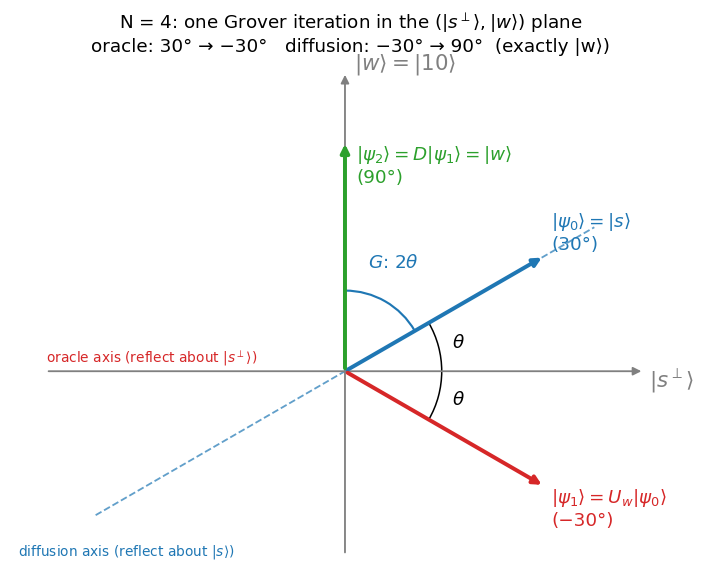

In [8]:
from matplotlib.patches import Arc

th = math.pi / 6
fig, ax = plt.subplots(figsize=(6.6, 6.6))
ax.set_aspect("equal"); ax.grid(False)
ax.set_xlim(-1.45, 1.5); ax.set_ylim(-0.85, 1.35); ax.axis("off")

# axes: |s_perp> horizontal, |w> vertical
ax.annotate("", xy=(1.3, 0), xytext=(-1.3, 0), arrowprops=dict(arrowstyle="-|>", color="gray", lw=1.2))
ax.annotate("", xy=(0, 1.3), xytext=(0, -0.8), arrowprops=dict(arrowstyle="-|>", color="gray", lw=1.2))
ax.text(1.32, -0.07, r"$|s^\perp\rangle$", fontsize=14, color="gray")
ax.text(0.04, 1.31, r"$|w\rangle=|10\rangle$", fontsize=14, color="gray")

# the diffusion axis (the line through |s>), dashed
L = 1.25
ax.plot([-L * math.cos(th), L * math.cos(th)], [-L * math.sin(th), L * math.sin(th)], "--", color=C_GROVER, lw=1.2, alpha=0.7)
ax.text(-1.42, -0.80, "diffusion axis (reflect about $|s\\rangle$)", fontsize=9, color=C_GROVER)
ax.text(-1.30, 0.04, "oracle axis (reflect about $|s^\\perp\\rangle$)", fontsize=9, color=C_CLASSICAL)

def vec(angle, color, label, dx, dy):
    a = math.radians(angle)
    ax.annotate("", xy=(math.cos(a), math.sin(a)), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2.6))
    ax.text(math.cos(a) + dx, math.sin(a) + dy, label, fontsize=12, color=color)

vec(30,  C_GROVER,    r"$|\psi_0\rangle=|s\rangle$" + "\n(30°)",           0.03, 0.03)
vec(-30, C_CLASSICAL, r"$|\psi_1\rangle=U_w|\psi_0\rangle$" + "\n(−30°)", 0.03, -0.17)
vec(90,  C_SUCCESS,   r"$|\psi_2\rangle=D|\psi_1\rangle=|w\rangle$" + "\n(90°)", 0.05, -0.18)

for t1, t2, lab, r in [(0, 30, r"$\theta$", 0.42), (-30, 0, r"$\theta$", 0.42)]:
    ax.add_patch(Arc((0, 0), 2 * r, 2 * r, theta1=t1, theta2=t2, color="black", lw=1))
    m = math.radians((t1 + t2) / 2)
    ax.text((r + 0.06) * math.cos(m), (r + 0.06) * math.sin(m) - 0.02, lab, fontsize=12)
ax.add_patch(Arc((0, 0), 0.7, 0.7, theta1=30, theta2=90, color=C_GROVER, lw=1.4))
ax.text(0.10, 0.45, r"$G$: $2\theta$", fontsize=12, color=C_GROVER)

ax.set_title("N = 4: one Grover iteration in the $(|s^\\perp\\rangle,|w\\rangle)$ plane\n"
             "oracle: 30° → −30°   diffusion: −30° → 90°  (exactly |w⟩)", fontsize=12)
finish(fig, "n4_geometry.png")

### Success probability: derivation, and the exact $N=4$ values

Since $G$ is a rotation by $2\theta$ and $|s\rangle$ sits at angle $\theta$ from the $|s^\perp\rangle$ axis,

$$G^k|s\rangle=\cos\!\big((2k+1)\theta\big)\,|s^\perp\rangle+\sin\!\big((2k+1)\theta\big)\,|w\rangle .$$

The amplitude of the marked state is therefore $\sin((2k+1)\theta)$. Each of the $N-1$ unmarked states carries an equal share of $|s^\perp\rangle$, i.e. amplitude $\cos((2k+1)\theta)/\sqrt{N-1}$, so

$$\boxed{P_{\text{success}}(k)=\sin^2\!\big((2k+1)\theta\big)}\qquad\Longrightarrow\qquad P_{\text{success}}=1\iff(2k+1)\theta=\tfrac{\pi}{2}+m\pi .$$

For $N=4$, $\theta=\pi/6$ and $(2k+1)\theta=\tfrac{\pi}{2}$ at $k=1$ (and again at $k=4,7,\dots$). The table gives the exact amplitudes for $k=0,\dots,6$ and **verifies the formula against the explicit $4\times4$ matrix power** $(DU_w)^k|\psi_0\rangle$.

In [9]:
G4 = D * U_w                                             # one Grover iteration, explicit 4x4 matrix
psi = psi0
rows = []
for k in range(0, 7):
    a_w = sp.sin((2 * k + 1) * pi / 6)                   # amplitude of the marked state
    a_o = sp.simplify(sp.cos((2 * k + 1) * pi / 6) / sqrt(3))   # amplitude of each unmarked state
    predicted = Matrix([a_w if x == w else a_o for x in range(4)])
    rows.append({
        "k": k,
        "a_w = sin((2k+1)π/6)": str(a_w),
        "a_other = cos((2k+1)π/6)/√3": str(a_o),
        "P(w) = a_w²": str(sp.simplify(a_w ** 2)),
        "P(each other state)": str(sp.simplify(a_o ** 2)),
        "= explicit (D·U_w)^k |ψ0>": same(psi, predicted),
    })
    psi = G4 * psi                                       # next iteration, by brute-force matrix algebra
table_n4 = pd.DataFrame(rows).set_index("k")
display(table_n4)
print("Closed-form amplitudes agree with explicit matrix algebra for every k:",
      bool(table_n4.iloc[:, -1].all()))

,a_w = sin((2k+1)π/6),a_other = cos((2k+1)π/6)/√3,P(w) = a_w²,P(each other state),= explicit (D·U_w)^k |ψ0>
k,,,,,
0,1/2,1/2,1/4,1/4,True
1,1,0,1,0,True
2,1/2,-1/2,1/4,1/4,True
3,-1/2,-1/2,1/4,1/4,True
4,-1,0,1,0,True
5,-1/2,1/2,1/4,1/4,True
6,1/2,1/2,1/4,1/4,True


Closed-form amplitudes agree with explicit matrix algebra for every k: True


In [10]:
# symbolic proof that G = D U_w is a rotation by 2*theta, for a general angle theta
t = sp.symbols("theta", real=True)
s2 = Matrix([cos(t), sin(t)])                            # |s> in the basis (|s_perp>, |w>)
U2 = sp.diag(1, -1)                                      # oracle: flips the |w> component
D2 = 2 * s2 * s2.T - eye(2)                              # diffusion
G2 = D2 * U2
R  = Matrix([[cos(2 * t), -sin(2 * t)], [sin(2 * t), cos(2 * t)]])
print("D (2D basis) = [[cos2t, sin2t],[sin2t, -cos2t]] ->",
      sp.simplify(sp.expand_trig(D2 - Matrix([[cos(2*t), sin(2*t)], [sin(2*t), -cos(2*t)]]))) == zeros(2, 2))
print("G = D U_w is the rotation matrix R(2*theta)  ->", sp.simplify(sp.expand_trig(G2 - R)) == zeros(2, 2))
show(r"G=DU_w", G2.applyfunc(sp.simplify))

D (2D basis) = [[cos2t, sin2t],[sin2t, -cos2t]] -> True
G = D U_w is the rotation matrix R(2*theta)  -> True


<IPython.core.display.Math object>

**Reading the table.**

* $k=0$: amplitudes $\tfrac12$ everywhere, $P(w)=\tfrac14$, the blind guess of §4.2.
* **$k=1$: $a_w=1$, all others $0$, $P(w)=1$.** This is the optimal iteration count, $k_{\text{opt}}=1$, and it agrees with §4.5.
* $k=2$ and $k=3$: $P(w)$ falls back to $\tfrac14$, **exactly as bad as guessing.** One iteration too many rotates the state *past* $|w\rangle$ (to $150^\circ$ and $210^\circ$), so more iterations are not better.
* $k=4$: the state has rotated a further full period and $P(w)=1$ again ($|a_w|=1$ with the opposite sign; the sign is a global phase).

These are exactly the values $0.25,\,1,\,0.25,\,0.25,\,1$ plotted for $N=4$ in the success-probability figure of §8.2.

### Independence of the marked element, and the one-qubit case

**All four choices of $w$.** $D=\tfrac12J-I$ is unchanged by any permutation of the basis states (the all-ones matrix $J$ is invariant), so relabelling the basis moves $w$ without changing anything else. The derivation of §4.2–4.5 therefore holds for every $w\in\{00,01,10,11\}$. Only the stage-1 $X$ gates of the oracle change: they are placed on the qubits where $w$ has a 0-bit. The table checks all four cases exactly.

In [11]:
def unit(i):
    e = zeros(4, 1); e[i] = 1
    return e

rows = []
for ww in range(4):
    b1, b0 = (ww >> 1) & 1, ww & 1
    Xs, x_gates = eye(4), []
    if b0 == 0: Xs = X_q0 * Xs; x_gates.append("X on q0")
    if b1 == 0: Xs = X_q1 * Xs; x_gates.append("X on q1")
    U_def = eye(4) - 2 * unit(ww) * unit(ww).T             # definition  I - 2|w><w|
    U_circ = Xs * CZ * Xs                                 # X-gates . CZ . X-gates
    final = D * U_def * psi0                              # one full Grover iteration
    e = unit(ww)
    rows.append({
        "marked w": f"|{ww:02b}>",
        "stage-1 X gates": ", ".join(x_gates) if x_gates else "none",
        "diag(U_w)": str([U_def[i, i] for i in range(4)]),
        "circuit X.CZ.X = U_w": same(U_circ, U_def),
        "state after one iteration": " + ".join(f"{str(final[i])}|{i:02b}>" for i in range(4) if final[i] != 0),
        "P(w)": str(sp.simplify(abs(final[ww]) ** 2)),
        "= |w> exactly": same(final, e),
    })
display(pd.DataFrame(rows).set_index("marked w"))

,stage-1 X gates,diag(U_w),circuit X.CZ.X = U_w,state after one iteration,P(w),= |w> exactly
marked w,,,,,,
|00>,"X on q0, X on q1","[-1, 1, 1, 1]",True,1|00>,1,True
|01>,X on q1,"[1, -1, 1, 1]",True,1|01>,1,True
|10>,X on q0,"[1, 1, -1, 1]",True,1|10>,1,True
|11>,none,"[1, 1, 1, -1]",True,1|11>,1,True


**The one-qubit case, $N=2$.** With $n=1$: $|s\rangle=|+\rangle$, $\theta=\arcsin\frac1{\sqrt2}=\frac\pi4$. Marking $w=|1\rangle$, the oracle is $U_w=Z$ and the diffusion is $D=2|+\rangle\langle+|-I=X$. One iteration gives $|+\rangle\xrightarrow{Z}|-\rangle\xrightarrow{X}-|-\rangle$, whose probability of $|1\rangle$ is still $\tfrac12$. In general $P(k)=\sin^2\!\big((2k+1)\tfrac\pi4\big)=\tfrac12$ for every $k$: **with a single qubit Grover's algorithm cannot beat a coin flip**, because the initial angle $\theta=45^\circ$ is already so large that a $90^\circ$ rotation merely swaps the state between the two sides of the target. This is why $N=4$ is the smallest case where the algorithm is meaningful.

In [12]:
Z1 = sp.diag(1, -1)
plus = H1 * Matrix([1, 0])
D1 = 2 * plus * plus.T - eye(2)
print("1 qubit:  D = 2|+><+| - I  equals  X  ->", same(D1, X1))
psi = plus
out = []
for k in range(0, 6):
    out.append({"k": k, "P(|1>)": str(sp.simplify(abs(psi[1]) ** 2)),
                "formula sin^2((2k+1)pi/4)": str(sp.simplify(sp.sin((2 * k + 1) * pi / 4) ** 2))})
    psi = (D1 * Z1) * psi
display(pd.DataFrame(out).set_index("k").T)

1 qubit:  D = 2|+><+| - I  equals  X  -> True


k,0,1,2,3,4,5
P(|1>),1/2,1/2,1/2,1/2,1/2,1/2
formula sin^2((2k+1)pi/4),1/2,1/2,1/2,1/2,1/2,1/2


## Quantum building blocks: oracle and diffusion constructions

### Phase oracle construction

For a marked element $w$ with bit string $w_{n-1}\dots w_0$ the oracle $U_w=I-2|w\rangle\langle w|$ is built in three stages:

1. **X on every qubit where $w_i=0$**, which maps $|w\rangle\mapsto|11\dots1\rangle$.
2. **Multi-controlled Z** (MCZ) on $|11\dots1\rangle$, implemented as $H\cdot\text{MCX}\cdot H$ on the last qubit. This flips the sign of $|11\dots1\rangle$ only.
3. **X again** on the same qubits, which undoes stage 1 and moves the sign flip back onto $|w\rangle$.

The construction needs **no ancilla qubits**: $n$ qubits for $N=2^n$ elements.

In [13]:
def build_oracle(n, target, barriers=False):
    """Phase oracle U_w = I - 2|w><w| on n qubits (marks index `target`)."""
    if not 0 <= target < 2 ** n:
        raise ValueError(f"target {target} out of range for {n} qubits")
    qc = QuantumCircuit(n, name="Oracle")
    bits = format(target, f"0{n}b")[::-1]            # little-endian: bits[i] is qubit i
    zeros = [i for i, b in enumerate(bits) if b == "0"]

    if zeros:
        qc.x(zeros)                                   # stage 1: |w> -> |11...1>
    if barriers:
        qc.barrier()
    qc.h(n - 1)                                       # stage 2: multi-controlled Z
    qc.mcx(list(range(n - 1)), n - 1)                 #          = H . MCX . H
    qc.h(n - 1)
    if barriers:
        qc.barrier()
    if zeros:
        qc.x(zeros)                                   # stage 3: undo stage 1
    return qc

### Oracle circuits for N = 4, 8, 16 and 32

One oracle per required search-space size. The marked elements below were chosen to contain both 0 and 1 bits, so the X-gate pattern of stage 1 is visible: $w=2=|10\rangle$, $w=5=|101\rangle$, $w=10=|1010\rangle$, $w=21=|10101\rangle$.

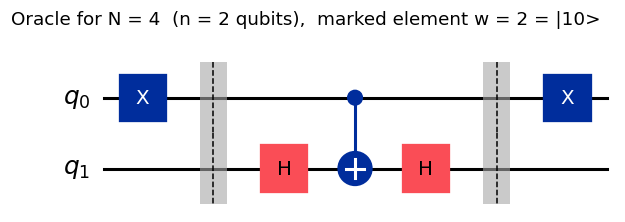

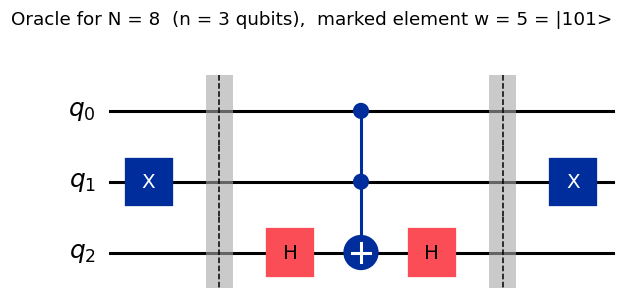

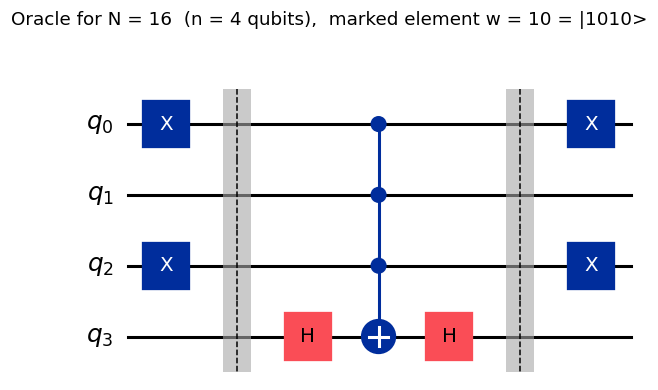

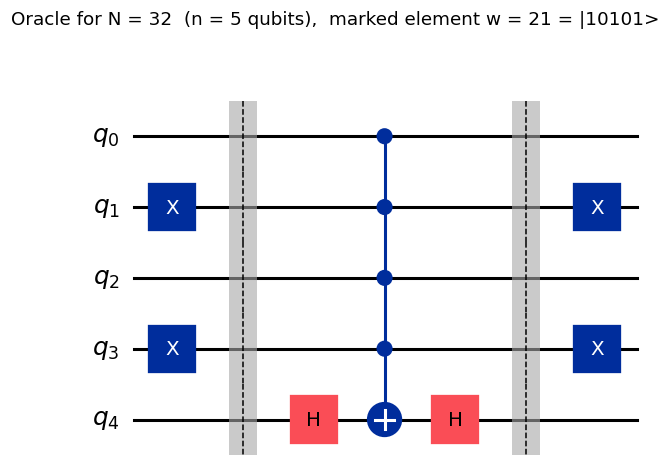

In [14]:
ORACLE_DEMO = {2: 2, 3: 5, 4: 10, 5: 21}          # n -> marked element w

for n, w in ORACLE_DEMO.items():
    N = 2 ** n
    fig = build_oracle(n, w, barriers=True).draw("mpl", fold=-1)
    fig.suptitle(f"Oracle for N = {N}  (n = {n} qubits),  marked element w = {w} = |{w:0{n}b}>",
                 fontsize=12, y=1.02)
    display(fig)
    plt.close(fig)

### Verifying the oracles

A drawing is not a proof, so the oracles are checked numerically against the definition. The unitary of every oracle, for **every possible marked element** of each size N = 4, 8, 16, 32, is compared with the ideal matrix $I-2|w\rangle\langle w|$ (the identity with a single $-1$ on the diagonal at position $w$).

In [15]:
rows = []
for n in range(2, 6):
    N = 2 ** n
    ok = 0
    for w in range(N):
        ideal = np.eye(N)
        ideal[w, w] = -1
        if np.allclose(Operator(build_oracle(n, w)).data, ideal):
            ok += 1
    rows.append({"N": N, "qubits n": n, "marked elements tested": N, "oracles exactly correct": ok,
                 "all correct": ok == N})
display(pd.DataFrame(rows).set_index("N"))

,qubits n,marked elements tested,oracles exactly correct,all correct
N,,,,
4,2,4,4,True
8,3,8,8,True
16,4,16,16,True
32,5,32,32,True


The next table shows what the oracle does to the uniform superposition for $N=8$, $w=5$: it leaves every amplitude alone except the marked one, whose sign flips. The oracle never changes any measurement probability on its own. The speed-up comes from what the *diffusion* step does with that hidden sign.

In [16]:
n, w = 3, 5
N = 2 ** n
O = build_oracle(n, w)
psi0 = Statevector.from_label("+" * n)           # uniform superposition |s>
psi1 = psi0.evolve(O)                            # after the oracle

table = pd.DataFrame({
    "x": range(N),
    "bits": [format(x, f"0{n}b") for x in range(N)],
    "f(x)": [int(x == w) for x in range(N)],
    "amplitude before (×√N)": np.round(psi0.data.real * np.sqrt(N), 3),
    "amplitude after oracle (×√N)": np.round(psi1.data.real * np.sqrt(N), 3),
    "probability after oracle": np.round(np.abs(psi1.data) ** 2, 4),
}).set_index("x")
display(table)

,bits,f(x),amplitude before (×√N),amplitude after oracle (×√N),probability after oracle
x,,,,,
0,000,0,1.0,1.0,0.125
1,001,0,1.0,1.0,0.125
2,010,0,1.0,1.0,0.125
3,011,0,1.0,1.0,0.125
4,100,0,1.0,1.0,0.125
5,101,1,1.0,-1.0,0.125
6,110,0,1.0,1.0,0.125
7,111,0,1.0,1.0,0.125


### Diffusion operator

The diffusion operator $D=2|s\rangle\langle s|-I$ reflects every amplitude about the mean. It is built as

$$D \;=\; H^{\otimes n}\,X^{\otimes n}\,\big(\text{MCZ}\big)\,X^{\otimes n}\,H^{\otimes n}\quad(\text{up to a global phase of }-1).$$

The product above equals $I-2|s\rangle\langle s|$, which is $-D$. A global phase of $\pi$ is added so the circuit is *exactly* $2|s\rangle\langle s|-I$; it has no observable effect on any measurement outcome.

,qubits n,equals 2|s><s| - I exactly
N,,
4,2,True
8,3,True
16,4,True
32,5,True


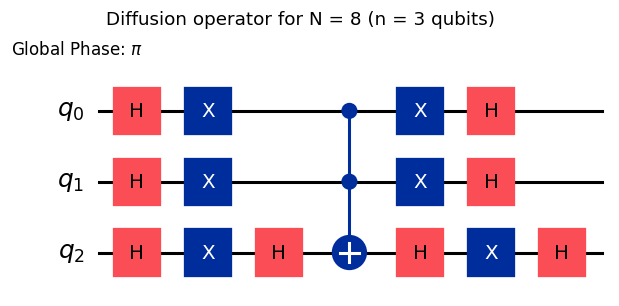

In [17]:
def build_diffusion(n):
    """Grover diffusion operator D = 2|s><s| - I on n qubits."""
    qc = QuantumCircuit(n, name="Diffusion")
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)                # multi-controlled Z on |11...1>
    qc.h(n - 1)
    qc.x(range(n))
    qc.h(range(n))
    qc.global_phase = math.pi                        # makes it exactly 2|s><s| - I
    return qc


# verify against the definition for all four sizes
rows = []
for n in range(2, 6):
    N = 2 ** n
    s = np.ones(N) / np.sqrt(N)
    ideal = 2 * np.outer(s, s) - np.eye(N)
    rows.append({"N": N, "qubits n": n,
                 "equals 2|s><s| - I exactly": np.allclose(Operator(build_diffusion(n)).data, ideal)})
display(pd.DataFrame(rows).set_index("N"))

fig = build_diffusion(3).draw("mpl", fold=-1)
fig.suptitle("Diffusion operator for N = 8 (n = 3 qubits)", fontsize=12, y=1.02)
display(fig)
plt.close(fig)

### One Grover iteration, step by step (N = 8)

The figure follows the real amplitudes of the 8 basis states through two Grover iterations. The oracle flips the sign of the marked amplitude (red). The diffusion step then reflects every amplitude about the mean, which, because the mean has been pulled down by the negative amplitude, *amplifies* the marked one and shrinks the rest.

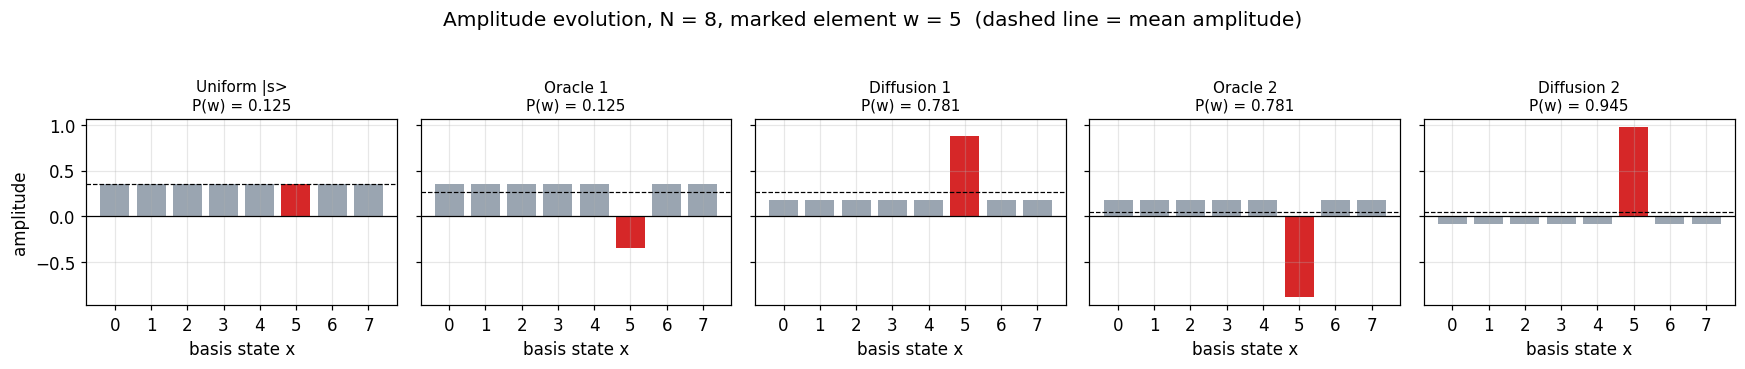

In [18]:
n, w = 3, 5
N = 2 ** n
O, D = build_oracle(n, w), build_diffusion(n)

steps = [("Uniform |s>", Statevector.from_label("+" * n))]
psi = steps[0][1]
for i in (1, 2):
    psi = psi.evolve(O);  steps.append((f"Oracle {i}", psi))
    psi = psi.evolve(D);  steps.append((f"Diffusion {i}", psi))

fig, axes = plt.subplots(1, len(steps), figsize=(16, 3.2), sharey=True)
for ax, (label, st) in zip(axes, steps):
    amp = st.data.real
    ax.bar(range(N), amp, color=[C_CLASSICAL if x == w else "#9aa5b1" for x in range(N)])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axhline(amp.mean(), color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"{label}\nP(w) = {abs(st.data[w])**2:.3f}", fontsize=10)
    ax.set_xlabel("basis state x")
    ax.set_xticks(range(N))
axes[0].set_ylabel("amplitude")
fig.suptitle(f"Amplitude evolution, N = {N}, marked element w = {w}  (dashed line = mean amplitude)", y=1.04)
finish(fig, "amplitude_evolution_N8.png")

## Quantum implementation on Qiskit Aer

### The Grover circuit

`build_grover_circuit` assembles the full algorithm: Hadamards, then $k$ repetitions of (oracle, diffusion), then measurement of all $n$ qubits.

The number of iterations $k$ is chosen with the exact formula from §2.2. For all sizes tested here it coincides with the usual approximation $\lfloor\tfrac{\pi}{4}\sqrt N\rfloor$ (checked in the table below).

In [19]:
def optimal_iterations(N):
    """k_opt = round(pi/(4*theta) - 1/2),  theta = arcsin(1/sqrt(N)),  at least 1."""
    theta = math.asin(1 / math.sqrt(N))
    return max(1, round(math.pi / (4 * theta) - 0.5))


def theoretical_success(N, k):
    """P(k) = sin^2((2k+1) theta)."""
    theta = math.asin(1 / math.sqrt(N))
    return math.sin((2 * k + 1) * theta) ** 2


def build_grover_circuit(n, target, k, measure=True, boxed=False):
    """Full Grover circuit: H^n, k x (oracle, diffusion), measure.

    boxed=True draws oracle/diffusion as labelled blocks (compact diagrams);
    boxed=False inlines every gate (used for execution and for depth/gate counts).
    """
    qr = QuantumRegister(n, "q")
    qc = QuantumCircuit(qr, ClassicalRegister(n, "c")) if measure else QuantumCircuit(qr)
    qc.h(qr)
    O, D = build_oracle(n, target), build_diffusion(n)
    for _ in range(k):
        if boxed:
            qc.append(O.to_gate(label="Oracle"), qr)
            qc.append(D.to_gate(label="Diffusion"), qr)
            qc.barrier()
        else:
            qc.compose(O, inplace=True)
            qc.compose(D, inplace=True)
    if measure:
        qc.measure(qr, qc.cregs[0])
    return qc


def exact_success_probability(n, target, k):
    """Ideal (noise-free, infinite-shot) probability of measuring the target."""
    sv = Statevector(build_grover_circuit(n, target, k, measure=False))
    return float(sv.probabilities()[target])


def run_on_aer(n, target, k, shots=SHOTS, seed=SEED):
    """Execute the Grover circuit on Qiskit Aer and return the counts dictionary."""
    qc = transpile(build_grover_circuit(n, target, k), SIM)
    return SIM.run(qc, shots=shots, seed_simulator=seed).result().get_counts()


def success_from_counts(counts, n, target, shots=SHOTS):
    return counts.get(format(target, f"0{n}b"), 0) / shots


# iteration counts: exact formula vs the (pi/4)*sqrt(N) approximation
rows = []
for n in range(2, 11):
    N = 2 ** n
    rows.append({
        "N": N, "n": n,
        "theta = asin(1/sqrt N)": round(math.asin(1 / math.sqrt(N)), 4),
        "(pi/4)*sqrt(N)": round(math.pi / 4 * math.sqrt(N), 2),
        "floor((pi/4)*sqrt N)": int(math.pi / 4 * math.sqrt(N)),
        "k_opt (exact formula)": optimal_iterations(N),
        "P(k_opt) theory": round(theoretical_success(N, optimal_iterations(N)), 4),
    })
display(pd.DataFrame(rows).set_index("N"))

,n,theta = asin(1/sqrt N),(pi/4)*sqrt(N),floor((pi/4)*sqrt N),k_opt (exact formula),P(k_opt) theory
N,,,,,,
4,2,0.5236,1.57,1,1,1.0000
8,3,0.3614,2.22,2,2,0.9453
16,4,0.2527,3.14,3,3,0.9613
32,5,0.1777,4.44,4,4,0.9992
64,6,0.1253,6.28,6,6,0.9966
128,7,0.0885,8.89,8,8,0.9956
256,8,0.0625,12.57,12,12,0.9999
512,9,0.0442,17.77,17,17,0.9994
1024,10,0.0313,25.13,25,25,0.9995


### Circuit diagrams for N = 4, 8, 16 and 32

Each circuit uses $k_{\text{opt}}$ Grover iterations and the same marked elements as in §5.2. The $N=4$ circuit is drawn with **every gate inlined**. The larger circuits use labelled *Oracle* / *Diffusion* blocks (the blocks are the circuits drawn in §5), separated by barriers, to stay readable.

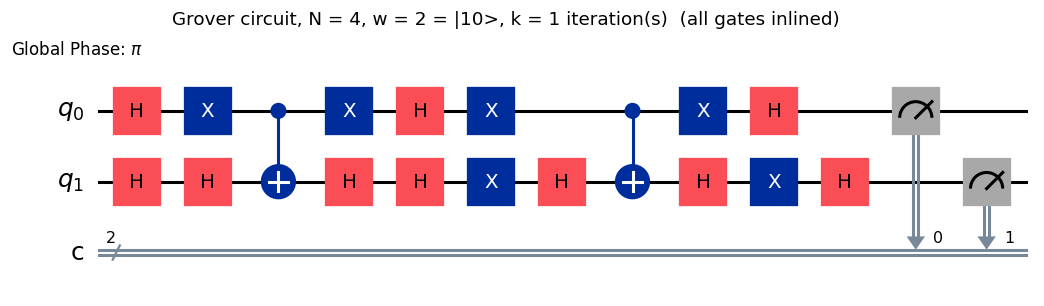

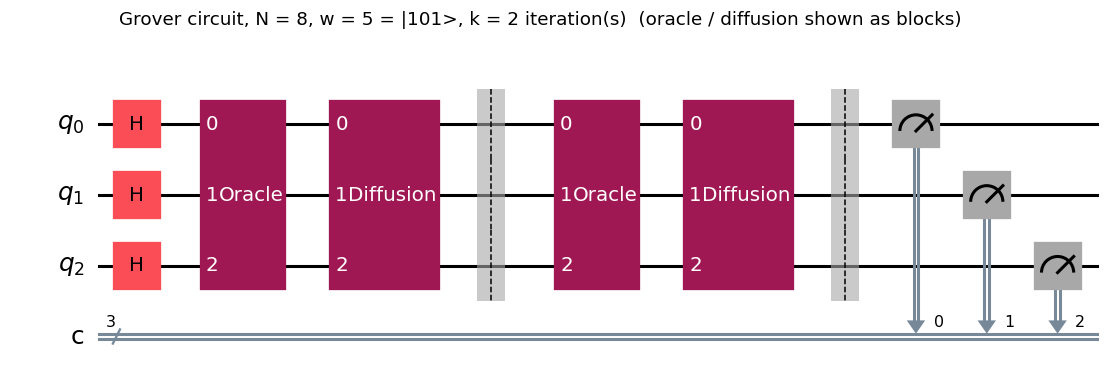

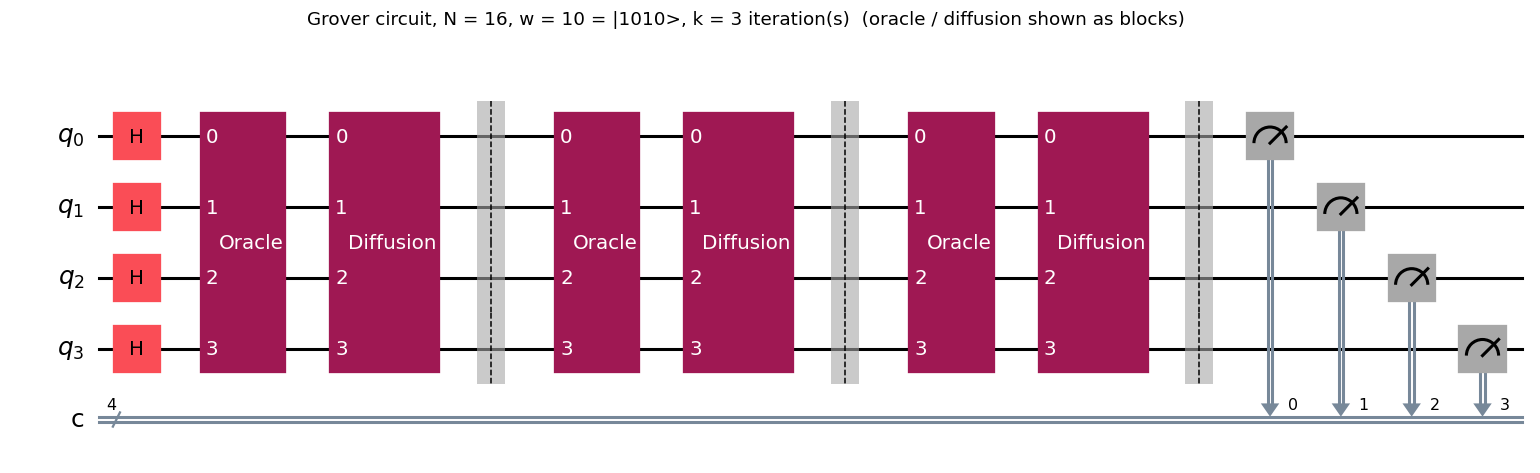

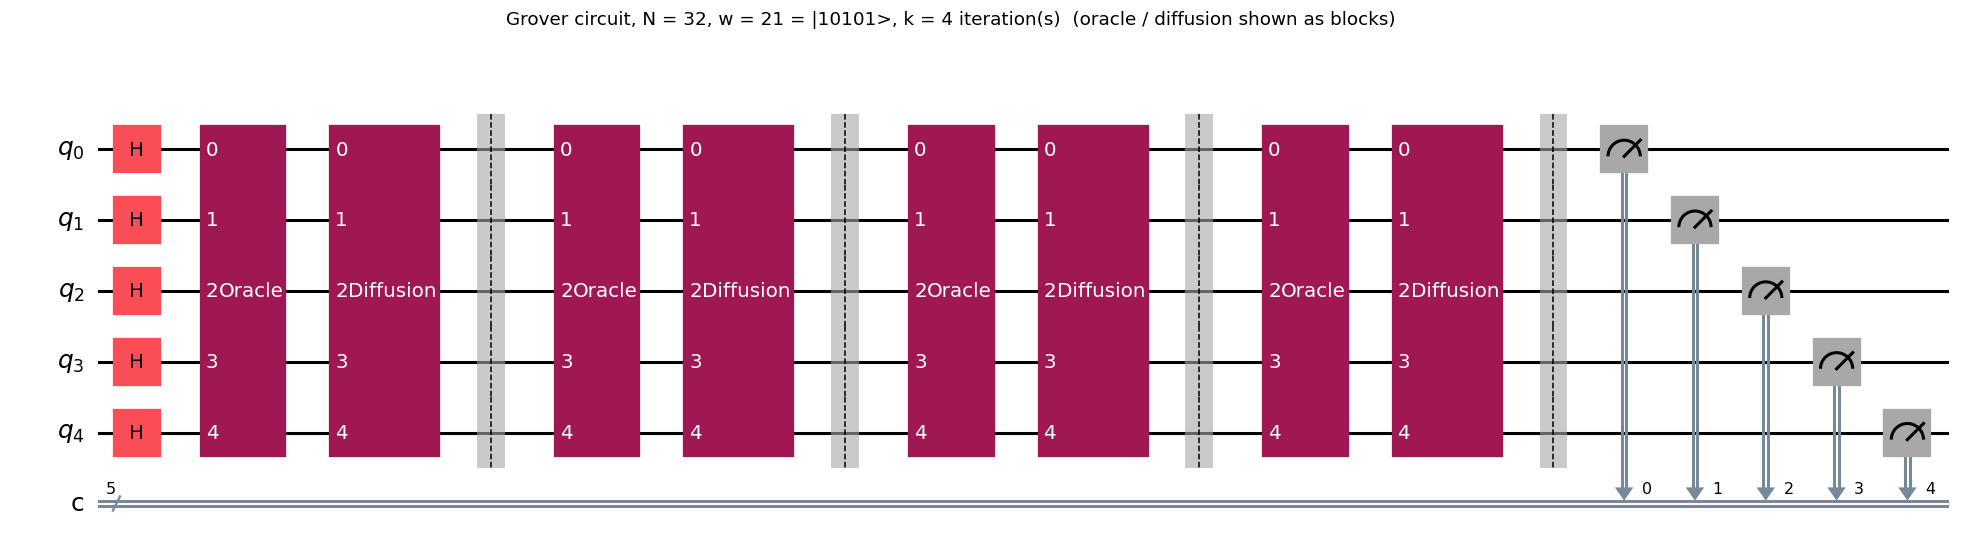

In [20]:
for n, w in ORACLE_DEMO.items():
    N, k = 2 ** n, optimal_iterations(2 ** n)
    qc = build_grover_circuit(n, w, k, boxed=(n > 2))
    fig = qc.draw("mpl", fold=-1)
    style = "all gates inlined" if n == 2 else "oracle / diffusion shown as blocks"
    fig.suptitle(f"Grover circuit, N = {N}, w = {w} = |{w:0{n}b}>, k = {k} iteration(s)  ({style})",
                 fontsize=12, y=1.02)
    display(fig)
    plt.close(fig)

### Running on Qiskit Aer

Every circuit is run for `SHOTS` shots. The table compares three numbers for the success probability: the **theoretical** value $\sin^2((2k+1)\theta)$, the **exact** value from the noise-free statevector (which validates that the circuits implement the theory), and the value **measured on Aer** (which carries ordinary shot noise of about $\sqrt{p(1-p)/\text{shots}}\approx0.4\%$ at $p\approx0.95$).

,qubits n,marked w,iterations k,P theory,P exact (statevector),"P measured (Aer, 4096 shots)",most frequent outcome,correct?
N,,,,,,,,
4,2,2 = 10,1,1.0000,1.0000,1.0000,10,True
8,3,5 = 101,2,0.9453,0.9453,0.9412,101,True
16,4,10 = 1010,3,0.9613,0.9613,0.9595,1010,True
32,5,21 = 10101,4,0.9992,0.9992,0.9995,10101,True


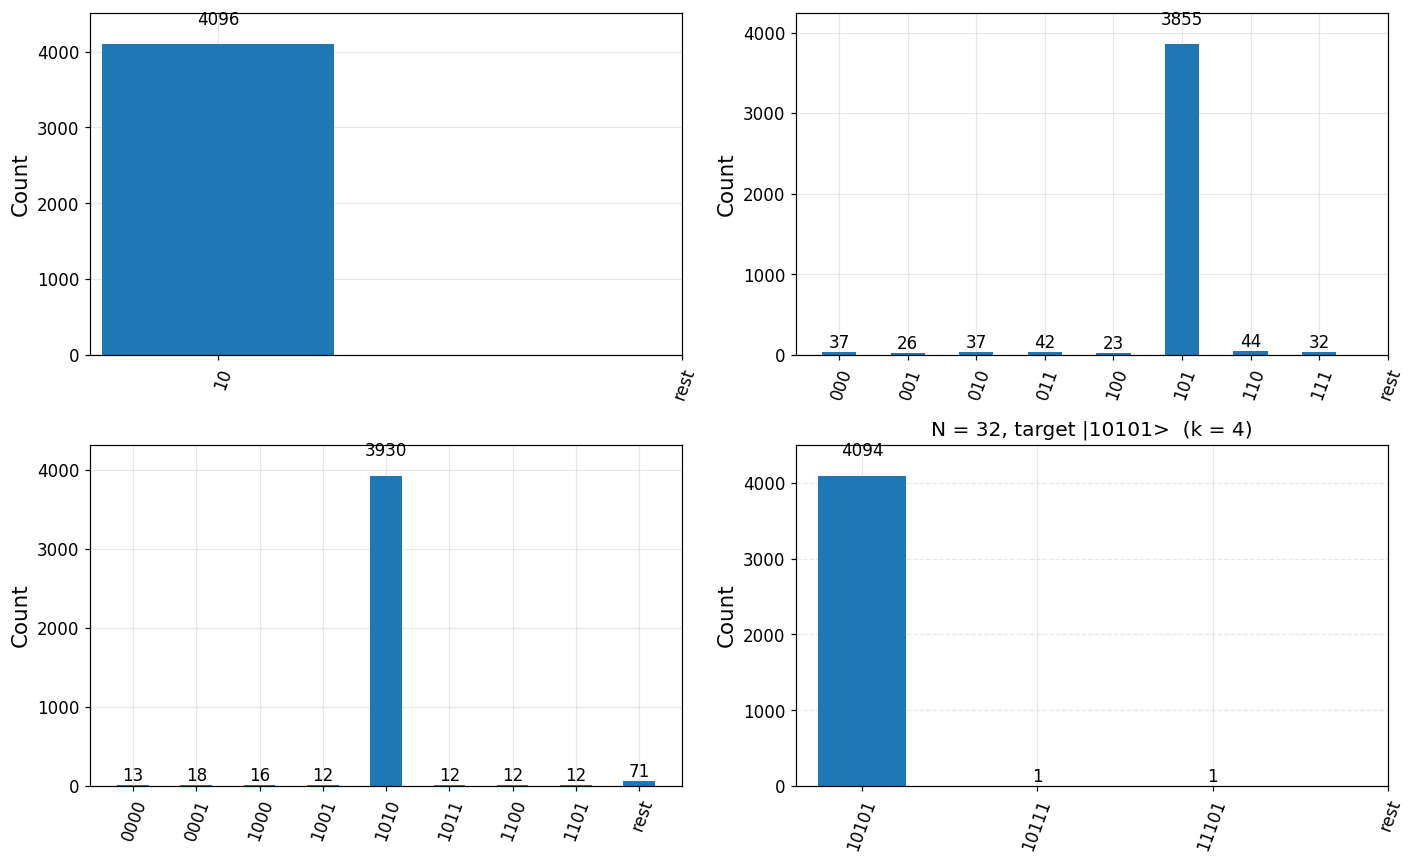

In [21]:
results_aer = {}
rows = []
for n, w in ORACLE_DEMO.items():
    N, k = 2 ** n, optimal_iterations(2 ** n)
    counts = run_on_aer(n, w, k)
    results_aer[n] = counts
    top = max(counts, key=counts.get)
    rows.append({
        "N": N, "qubits n": n, "marked w": f"{w} = {w:0{n}b}", "iterations k": k,
        "P theory": round(theoretical_success(N, k), 4),
        "P exact (statevector)": round(exact_success_probability(n, w, k), 4),
        f"P measured (Aer, {SHOTS} shots)": round(success_from_counts(counts, n, w), 4),
        "most frequent outcome": top,
        "correct?": top == format(w, f"0{n}b"),
    })
display(pd.DataFrame(rows).set_index("N"))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (n, w) in zip(axes.ravel(), ORACLE_DEMO.items()):
    plot_histogram(results_aer[n], ax=ax, number_to_keep=8, color=C_GROVER,
                   title=f"N = {2**n}, target |{w:0{n}b}>  (k = {optimal_iterations(2**n)})")
finish(fig, "aer_histograms.png")

**Result.** For every size the target is the most frequent outcome by a wide margin, and the measured probabilities agree with the exact statevector values within shot noise. The exact values agree with the closed-form theory, so the oracle, diffusion operator and iteration count are all correct. The small deficit from 100% (for example at $N=8$) is *not* hardware noise (the simulator is ideal). It is the inherent discreteness of Grover's algorithm: the state can only be rotated in steps of $2\theta$, so it generally lands slightly short of or past $|w\rangle$.

### Validation against the analytical treatment (N = 4)

The exact vectors derived in §4 give a precise, falsifiable test of the implementation. The Qiskit circuit for $N=4$ is built **stage by stage** and its statevector after each stage is compared with the hand-derived $|\psi_0\rangle,|\psi_1\rangle,|\psi_2\rangle$ of §4. Then, for **every** possible marked element, the full circuit is run on Aer: §4.8 predicts the marked state must be the *only* outcome (probability exactly 1), so even a single wrong shot would indicate a bug.

In [22]:
# expected states: taken directly from the exact SymPy derivation of section 4
expected = {
    "after H⊗H   (ψ0)":           np.array(EXACT_N4["psi0"].tolist(), dtype=float).ravel(),
    "after oracle (ψ1)":          np.array(EXACT_N4["psi1"].tolist(), dtype=float).ravel(),
    "after diffusion (ψ2)":       np.array(EXACT_N4["psi2"].tolist(), dtype=float).ravel(),
}

n, w_ = 2, 2                                              # N = 4, marked |10>, as in section 4
qc = QuantumCircuit(n)
stage_states = {}
qc.h(range(n));                                   stage_states["after H⊗H   (ψ0)"]     = Statevector(qc)
qc.compose(build_oracle(n, w_), inplace=True);    stage_states["after oracle (ψ1)"]    = Statevector(qc)
qc.compose(build_diffusion(n), inplace=True);     stage_states["after diffusion (ψ2)"] = Statevector(qc)

rows = []
for name, sv in stage_states.items():
    rows.append({
        "stage": name,
        "Qiskit amplitudes (|00>,|01>,|10>,|11>)": (np.round(sv.data.real, 6) + 0.0).tolist(),
        "analytical amplitudes": (expected[name].round(6) + 0.0).tolist(),
        "imaginary parts all 0": bool(np.allclose(sv.data.imag, 0)),
        "match": bool(np.allclose(sv.data, expected[name])),
    })
display(pd.DataFrame(rows).set_index("stage"))

# every marked element, full circuit on Aer: the marked state must be the ONLY outcome
rows = []
for target in range(4):
    counts = run_on_aer(2, target, 1)
    rows.append({
        "marked w": f"|{target:02b}>",
        "Aer counts": dict(counts),
        "P(w) measured": success_from_counts(counts, 2, target),
        "analytical P(w)": 1.0,
        "only outcome is w": set(counts) == {format(target, "02b")},
    })
validation = pd.DataFrame(rows).set_index("marked w")
display(validation)
stages_ok = all(bool(np.allclose(sv.data, expected[nm])) for nm, sv in stage_states.items())
print("Implementation reproduces the analytical N = 4 treatment at every stage:", stages_ok,
      "| all four marked elements found with certainty:", bool(validation["only outcome is w"].all()))

,"Qiskit amplitudes (|00>,|01>,|10>,|11>)",analytical amplitudes,imaginary parts all 0,match
stage,,,,
after H⊗H (ψ0),"[0.5, 0.5, 0.5, 0.5]","[0.5, 0.5, 0.5, 0.5]",True,True
after oracle (ψ1),"[0.5, 0.5, -0.5, 0.5]","[0.5, 0.5, -0.5, 0.5]",True,True
after diffusion (ψ2),"[0.0, 0.0, 1.0, 0.0]","[0.0, 0.0, 1.0, 0.0]",True,True


,Aer counts,P(w) measured,analytical P(w),only outcome is w
marked w,,,,
|00>,{'00': 4096},1.0,1.0,True
|01>,{'01': 4096},1.0,1.0,True
|10>,{'10': 4096},1.0,1.0,True
|11>,{'11': 4096},1.0,1.0,True


Implementation reproduces the analytical N = 4 treatment at every stage: True | all four marked elements found with certainty: True


##Searching a real dataset

To show the algorithm on actual data, both searches are run on the project's bundled dataset `data/dataset.csv` (a table of student numbers and names). The dataset has $256=2^8$ rows, so the search index fits exactly in $n=8$ qubits. If a dataset's size is not a power of two it is padded up to the next power of two ($n=\lceil\log_2 N\rceil$ qubits), and the padding entries are simply never marked.

Because names repeat in this dataset, only names that occur **exactly once** are used as targets (Grover with one marked element requires a unique solution).

In [23]:
if ROOT is not None:
    df = pd.read_csv(ROOT / "data" / "dataset.csv", encoding="utf-8-sig")   # utf-8-sig strips the BOM
else:                                                                         # fallback so the notebook still runs
    df = pd.DataFrame({"id": range(256), "name": [f"item_{i}" for i in range(256)]})

items = df["name"].astype(str).tolist()
N_items = len(items)
n_q = max(1, (N_items - 1).bit_length())
name_counts = df["name"].value_counts()
unique_pos = [i for i, nm in enumerate(items) if name_counts[nm] == 1]

print(f"rows: {N_items}   distinct names: {df['name'].nunique()}   unique-once names: {len(unique_pos)}")
print(f"qubits needed: n = ceil(log2 {N_items}) = {n_q}   padded search space: {2 ** n_q}\n")

picks = [unique_pos[0], unique_pos[len(unique_pos) // 2], unique_pos[-1]]
if "Zoe" in items and name_counts["Zoe"] == 1:
    picks.insert(2, items.index("Zoe"))
picks = sorted(set(picks))

rows = []
k_ds = optimal_iterations(2 ** n_q)
for idx in picks:
    target = items[idx]
    _, classical_q = linear_search(items, target)
    counts = run_on_aer(n_q, idx, k_ds)
    best = max(counts, key=counts.get)
    found_idx = int(best, 2)
    rows.append({
        "target name": target, "true index": idx,
        "classical queries": classical_q,
        "Grover queries (k)": k_ds,
        "P(success) measured": round(success_from_counts(counts, n_q, idx), 4),
        "Grover returned index": found_idx,
        "Grover returned name": items[found_idx] if found_idx < N_items else "(padding)",
        "correct?": found_idx == idx,
    })
display(pd.DataFrame(rows).set_index("target name"))

rows: 256   distinct names: 256   unique-once names: 256
qubits needed: n = ceil(log2 256) = 8   padded search space: 256



,true index,classical queries,Grover queries (k),P(success) measured,Grover returned index,Grover returned name,correct?
target name,,,,,,,
item_0,0,1,12,1.0,0,item_0,True
item_128,128,129,12,1.0,128,item_128,True
item_255,255,256,12,1.0,255,item_255,True


**Result.** The classical cost depends on *where* the target sits (1 query for the first row, 256 for the last), whereas Grover's cost is the same $k$ oracle calls for every target, because it does not exploit the order of the data. In every case Grover returns the correct index and maps it back to the right name.

## Analysis

All experiments below use the functions defined above. The main sweep covers $n=2,\dots,10$ qubits ($N=4,\dots,1024$), which includes the four required sizes $N=4,8,16,32$ and extends the trend to show the scaling clearly. For each size the marked element is $w=N-1$ (the worst case for the classical scan).

### Experiment sweep

For each $N$, the sweep records the classical query count, the number of Grover iterations, the success probability (theory, exact, Aer), and the circuit metrics. Two depth figures are reported:

* **logical depth** counts the multi-controlled-X as *one* gate (the circuit as written);
* **transpiled depth** decomposes everything into the hardware-style basis `{u, cx}` (`optimization_level=1`), which is the realistic cost on a device that only has one- and two-qubit gates.

In [24]:
def circuit_metrics(n, target, k):
    """Depth and gate counts of the full Grover circuit (including the final measurement)."""
    qc = build_grover_circuit(n, target, k)
    tq = transpile(qc, basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=SEED)
    ops = tq.count_ops()
    return {
        "logical_depth": qc.depth(), "logical_gates": qc.size(),
        "transpiled_depth": tq.depth(), "transpiled_gates": tq.size(),
        "cx_gates": ops.get("cx", 0),
    }


def iteration_metrics(n, target):
    """Transpiled depth / cx count of ONE Grover iteration (oracle followed by diffusion)."""
    qc = QuantumCircuit(n)
    qc.compose(build_oracle(n, target), inplace=True)
    qc.compose(build_diffusion(n), inplace=True)
    tq = transpile(qc, basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=SEED)
    return tq.depth(), tq.count_ops().get("cx", 0)


rows = []
t0 = time.time()
for n in range(2, 11):
    N, w = 2 ** n, 2 ** n - 1
    k = optimal_iterations(N)
    _, classical_worst = linear_search(list(range(N)), w)
    p_exact = exact_success_probability(n, w, k)
    p_aer = success_from_counts(run_on_aer(n, w, k), n, w)
    it_depth, it_cx = iteration_metrics(n, w)
    rows.append({
        "N": N, "n_qubits": n,
        "classical_worst": classical_worst, "classical_avg": (N + 1) / 2,
        "grover_queries": k,
        "speedup_vs_worst": classical_worst / k,
        "p_theory": theoretical_success(N, k), "p_exact": p_exact, "p_aer": p_aer,
        "expected_queries_with_retry": k / p_exact,
        **circuit_metrics(n, w, k),
        "depth_per_iteration": it_depth, "cx_per_iteration": it_cx,
    })
sweep = pd.DataFrame(rows)
print(f"sweep finished in {time.time() - t0:.1f} s")

display(sweep[["N", "n_qubits", "classical_worst", "classical_avg", "grover_queries",
               "speedup_vs_worst", "p_theory", "p_exact", "p_aer"]]
        .style.format({"classical_avg": "{:.1f}", "speedup_vs_worst": "{:.1f}",
                       "p_theory": "{:.4f}", "p_exact": "{:.4f}", "p_aer": "{:.4f}"})
        .hide(axis="index"))

sweep finished in 7.2 s


N,n_qubits,classical_worst,classical_avg,grover_queries,speedup_vs_worst,p_theory,p_exact,p_aer
4,2,4,2.5,1,4.0,1.0000,1.0000,1.0000
8,3,8,4.5,2,4.0,0.9453,0.9453,0.9424
16,4,16,8.5,3,5.3,0.9613,0.9613,0.9600
32,5,32,16.5,4,8.0,0.9992,0.9992,0.9990
64,6,64,32.5,6,10.7,0.9966,0.9966,0.9963
128,7,128,64.5,8,16.0,0.9956,0.9956,0.9932
256,8,256,128.5,12,21.3,0.9999,0.9999,1.0000
512,9,512,256.5,17,30.1,0.9994,0.9994,1.0000
1024,10,1024,512.5,25,41.0,0.9995,0.9995,1.0000


### Query count vs N

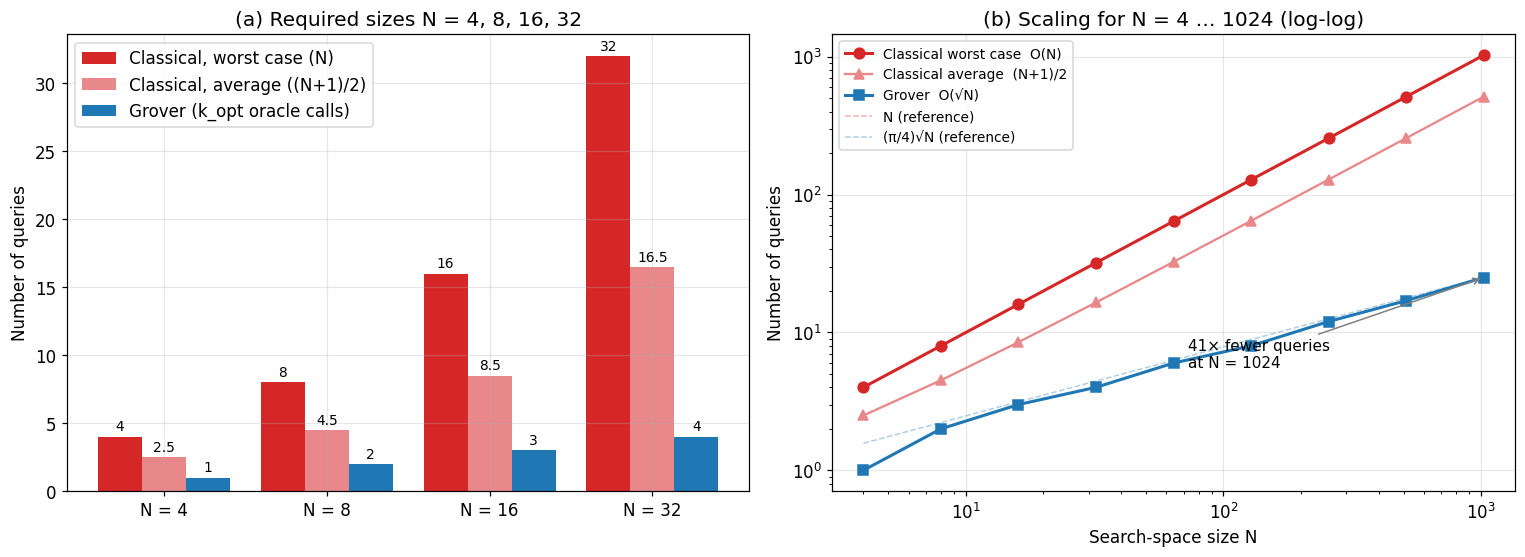

Fitted exponent  queries ~ N^a :   classical a = 1.000   Grover a = 0.547
Speed-up (classical worst / Grover) at N = 4, 8, 16, 32, 1024: 4.0x, 4.0x, 5.3x, 8.0x, 41.0x


In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# (a) required sizes, grouped bars
req = sweep[sweep["N"].isin([4, 8, 16, 32])]
x = np.arange(len(req)); wdt = 0.27
b1 = ax1.bar(x - wdt, req["classical_worst"], wdt, color=C_CLASSICAL, label="Classical, worst case (N)")
b2 = ax1.bar(x,        req["classical_avg"],  wdt, color="#e8888a",  label="Classical, average ((N+1)/2)")
b3 = ax1.bar(x + wdt,  req["grover_queries"], wdt, color=C_GROVER,   label="Grover (k_opt oracle calls)")
for bars in (b1, b2, b3):
    ax1.bar_label(bars, fmt="%g", padding=2, fontsize=9)
ax1.set_xticks(x); ax1.set_xticklabels([f"N = {n}" for n in req["N"]])
ax1.set_ylabel("Number of queries"); ax1.set_title("(a) Required sizes N = 4, 8, 16, 32")
ax1.legend(loc="upper left")

# (b) full sweep, log-log with theory curves
Ns = np.logspace(np.log10(sweep["N"].min()), np.log10(sweep["N"].max()), 200)
ax2.loglog(sweep["N"], sweep["classical_worst"], "o-", color=C_CLASSICAL, lw=2, ms=7, label="Classical worst case  O(N)")
ax2.loglog(sweep["N"], sweep["classical_avg"],   "^-", color="#e8888a",   lw=1.5, ms=6, label="Classical average  (N+1)/2")
ax2.loglog(sweep["N"], sweep["grover_queries"],  "s-", color=C_GROVER,    lw=2, ms=7, label="Grover  O(√N)")
ax2.loglog(Ns, Ns, "--", color=C_CLASSICAL, alpha=0.35, lw=1, label="N (reference)")
ax2.loglog(Ns, math.pi / 4 * np.sqrt(Ns), "--", color=C_GROVER, alpha=0.35, lw=1, label="(π/4)√N (reference)")
last = sweep.iloc[-1]
ax2.annotate(f"{last['speedup_vs_worst']:.0f}× fewer queries\nat N = {int(last['N'])}",
             xy=(last["N"], last["grover_queries"]), xytext=(last["N"] / 14, last["grover_queries"] / 4.5),
             arrowprops=dict(arrowstyle="->", color="gray"), fontsize=10)
ax2.set_xlabel("Search-space size N"); ax2.set_ylabel("Number of queries")
ax2.set_title("(b) Scaling for N = 4 … 1024 (log-log)")
ax2.legend(loc="upper left", fontsize=9)
finish(fig, "query_count_vs_N.png")

# empirical scaling exponents: slope of log(queries) vs log(N)
slope_c = np.polyfit(np.log(sweep["N"]), np.log(sweep["classical_worst"]), 1)[0]
slope_g = np.polyfit(np.log(sweep["N"]), np.log(sweep["grover_queries"]), 1)[0]
print(f"Fitted exponent  queries ~ N^a :   classical a = {slope_c:.3f}   Grover a = {slope_g:.3f}")
print(f"Speed-up (classical worst / Grover) at N = 4, 8, 16, 32, 1024: "
      + ", ".join(f"{s:.1f}x" for s in sweep[sweep['N'].isin([4, 8, 16, 32, 1024])]['speedup_vs_worst']))

### Success probability vs number of iterations

Here the number of iterations $k$ is swept from 0 (a random guess, $P=1/N$) through one full oscillation period for each of $N=4,8,16,32$. Each point is computed three ways: the closed form $\sin^2((2k+1)\theta)$ (line), the exact statevector (open circles) and the Aer measurement (filled squares).

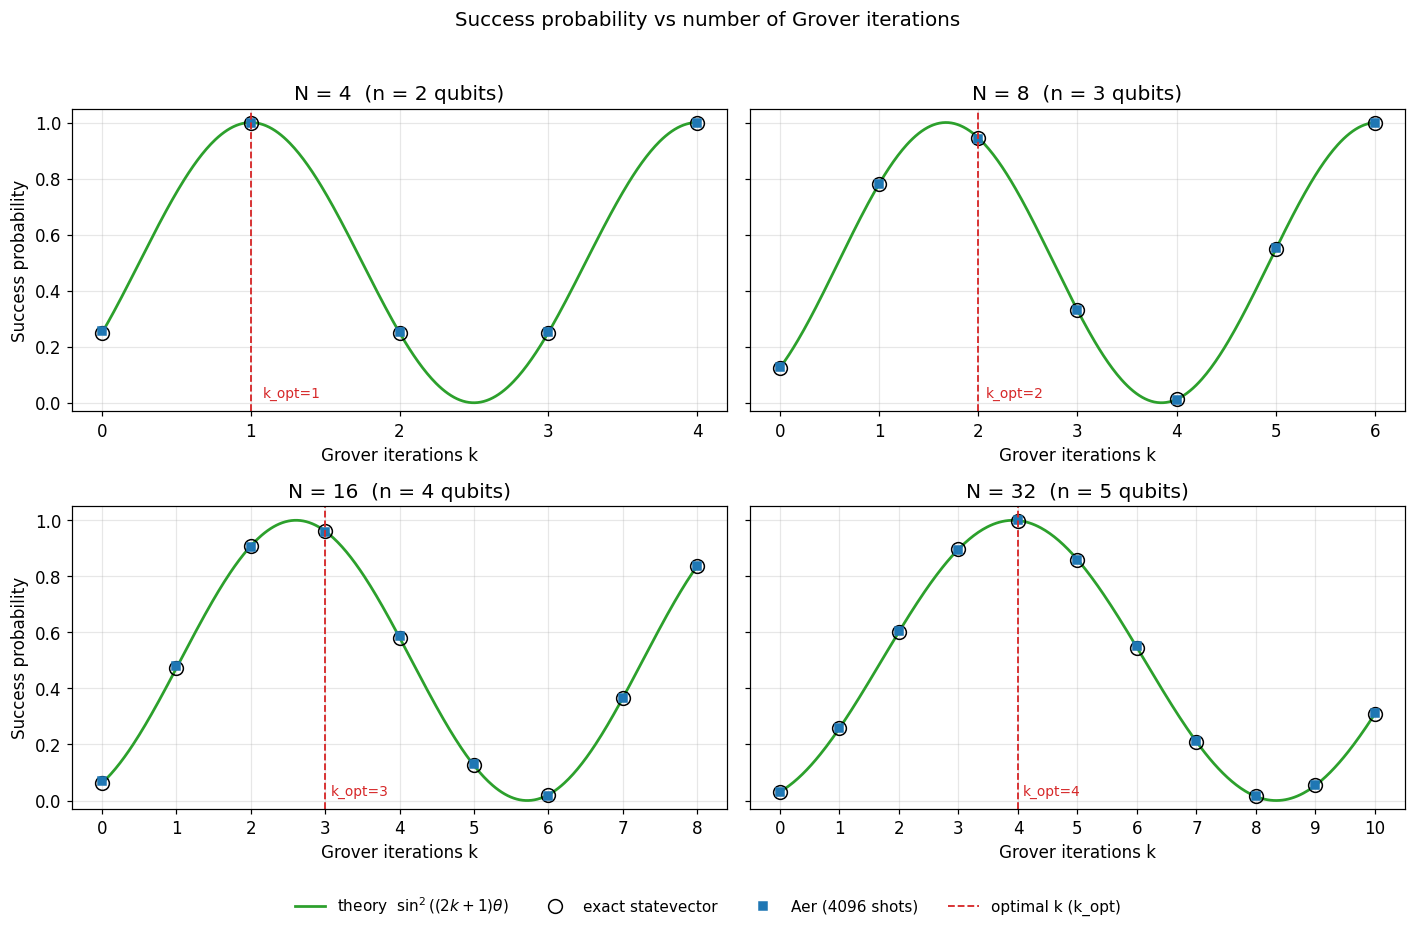

,N = 8 (exact P),N = 32 (exact P)
k,,
0,0.1250,0.0312
1,0.7812,0.2583
2,0.9453,0.6024
3,0.3301,0.8969
4,0.0122,0.9992
5,0.5480,0.8596
6,0.9998,0.5459
7,NaN,0.2099
8,NaN,0.0145


In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharey=True)
sweep_rows = []
for ax, (n, w) in zip(axes.ravel(), ORACLE_DEMO.items()):
    N = 2 ** n
    theta = math.asin(1 / math.sqrt(N))
    k_opt = optimal_iterations(N)
    k_max = math.ceil(math.pi / (2 * theta)) + 1          # one full period + 1

    ks = np.arange(0, k_max + 1)
    p_exact = np.array([exact_success_probability(n, w, int(k)) for k in ks])
    p_aer   = np.array([success_from_counts(run_on_aer(n, w, int(k)), n, w) for k in ks])
    for k, pe, pa in zip(ks, p_exact, p_aer):
        sweep_rows.append({"N": N, "k": int(k), "p_theory": theoretical_success(N, int(k)), "p_exact": pe, "p_aer": pa})

    kk = np.linspace(0, k_max, 400)
    ax.plot(kk, np.sin((2 * kk + 1) * theta) ** 2, "-", color=C_SUCCESS, lw=1.8, label=r"theory  $\sin^2((2k+1)\theta)$")
    ax.plot(ks, p_exact, "o", mfc="none", mec="black", ms=9, label="exact statevector")
    ax.plot(ks, p_aer, "s", color=C_GROVER, ms=5, label=f"Aer ({SHOTS} shots)")
    ax.axvline(k_opt, color=C_CLASSICAL, ls="--", lw=1.2, label="optimal k (k_opt)")
    ax.set_title(f"N = {N}  (n = {n} qubits)")
    ax.set_xlabel("Grover iterations k"); ax.set_ylim(-0.03, 1.05)
    ax.set_xticks(ks)
    ax.text(k_opt + 0.08, 0.02, f"k_opt={k_opt}", color=C_CLASSICAL, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Success probability")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=10, frameon=False)
fig.suptitle("Success probability vs number of Grover iterations", fontsize=13)
finish(fig, "success_vs_iterations.png", rect=[0, 0.05, 1, 0.96])

iter_table = pd.DataFrame(sweep_rows)
# worked example: what happens if one iteration too many is applied?
view = iter_table[iter_table["N"].isin([8, 32])].pivot(index="k", columns="N", values="p_exact").round(4)
view.columns = [f"N = {c} (exact P)" for c in view.columns]
display(view)

The probability at the *optimal* iteration count, as a function of $N$, is shown next. Theory guarantees $P(k_{\text{opt}})\ge 1-1/N$, and the curve tends to 1 as $N$ grows.

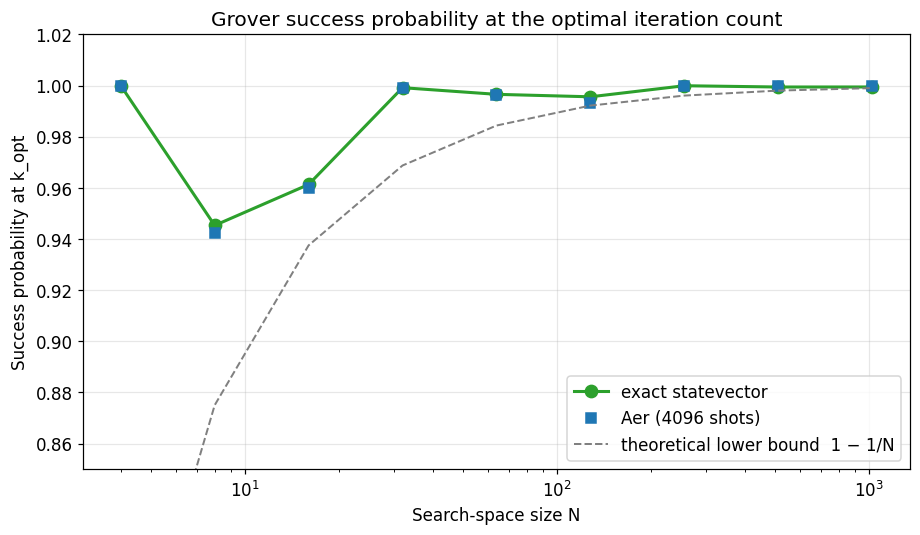

min exact P(k_opt) over the sweep : 0.9453 at N = 8
bound 1-1/N respected for all N   : True


In [27]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.semilogx(sweep["N"], sweep["p_exact"], "o-", color=C_SUCCESS, lw=2, ms=8, label="exact statevector")
ax.semilogx(sweep["N"], sweep["p_aer"], "s", color=C_GROVER, ms=7, label=f"Aer ({SHOTS} shots)")
ax.semilogx(sweep["N"], 1 - 1 / sweep["N"], "--", color="gray", lw=1.3, label="theoretical lower bound  1 − 1/N")
ax.set_xlabel("Search-space size N"); ax.set_ylabel("Success probability at k_opt")
ax.set_title("Grover success probability at the optimal iteration count")
ax.set_ylim(0.85, 1.02); ax.legend(loc="lower right")
finish(fig, "success_at_kopt_vs_N.png")

print("min exact P(k_opt) over the sweep :", round(sweep["p_exact"].min(), 4),
      "at N =", int(sweep.loc[sweep["p_exact"].idxmin(), "N"]))
print("bound 1-1/N respected for all N   :", bool((sweep["p_exact"] >= 1 - 1 / sweep["N"] - 1e-12).all()))

### Qubits vs N

Grover's algorithm indexes the $N$ elements with an $n$-qubit register, so $n=\lceil\log_2 N\rceil$. The constructions in this report use **no ancilla qubits**, so $n$ is the total qubit count.

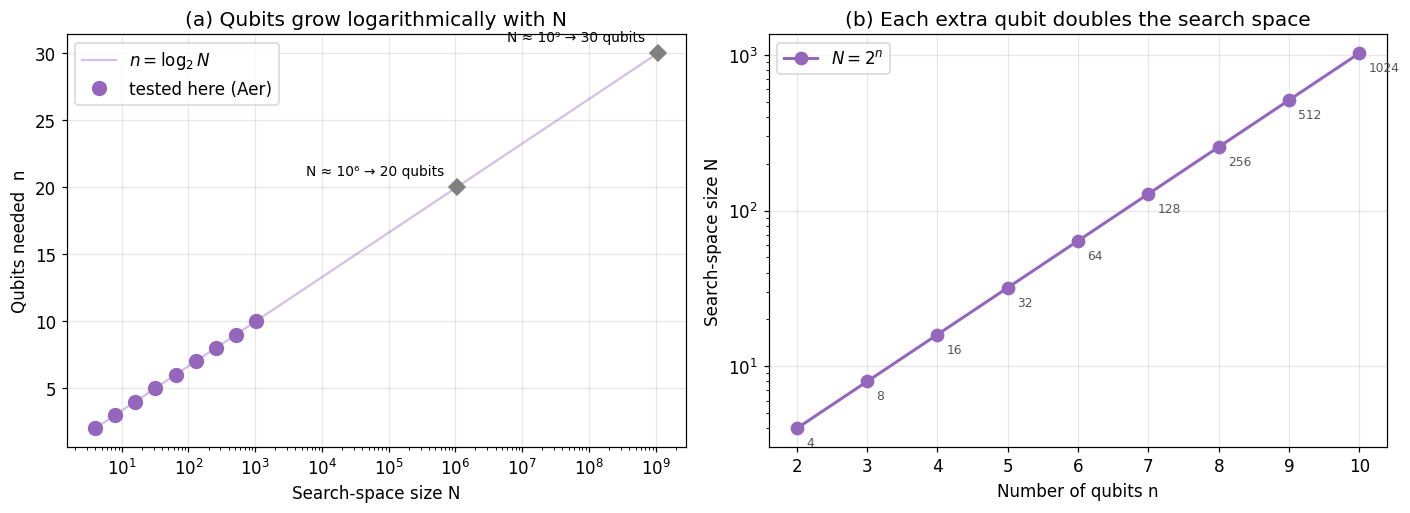

N,4,8,16,32,64,128,256,512,1024
qubits n,2,3,4,5,6,7,8,9,10


In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# (a) qubits needed vs N (log x-axis): a straight line, i.e. n = log2(N)
Ns = np.logspace(np.log10(4), np.log10(2 ** 30), 200)
ax1.semilogx(Ns, np.log2(Ns), "-", color=C_QUBITS, alpha=0.4, lw=1.5, label=r"$n=\log_2 N$")
ax1.semilogx(sweep["N"], sweep["n_qubits"], "o", color=C_QUBITS, ms=9, label="tested here (Aer)")
for N_, lab in [(2 ** 20, "N ≈ 10⁶ → 20 qubits"), (2 ** 30, "N ≈ 10⁹ → 30 qubits")]:
    ax1.plot(N_, math.log2(N_), "D", color="gray", ms=7)
    ax1.annotate(lab, (N_, math.log2(N_)), textcoords="offset points", xytext=(-8, 8), ha="right", fontsize=9)
ax1.set_xlabel("Search-space size N"); ax1.set_ylabel("Qubits needed  n")
ax1.set_title("(a) Qubits grow logarithmically with N"); ax1.legend(loc="upper left")

# (b) the same relation inverted: state-space size N = 2^n
ax2.semilogy(sweep["n_qubits"], sweep["N"], "o-", color=C_QUBITS, lw=2, ms=8, label=r"$N=2^n$")
for _, r in sweep.iterrows():
    ax2.annotate(f"{int(r['N'])}", (r["n_qubits"], r["N"]), textcoords="offset points", xytext=(6, -12), fontsize=8, color="#555")
ax2.set_xlabel("Number of qubits n"); ax2.set_ylabel("Search-space size N")
ax2.set_title("(b) Each extra qubit doubles the search space"); ax2.legend(loc="upper left")
finish(fig, "qubits_vs_N.png")

display(sweep[["N", "n_qubits"]].rename(columns={"n_qubits": "qubits n"}).set_index("N").T)

### Circuit depth and gate count

*Query* complexity counts oracle calls. A real device pays for **every gate**, and each oracle call and diffusion step contains an $n$-qubit multi-controlled gate whose cost grows with $n$. The two depth measures defined in §8.0 show the difference.

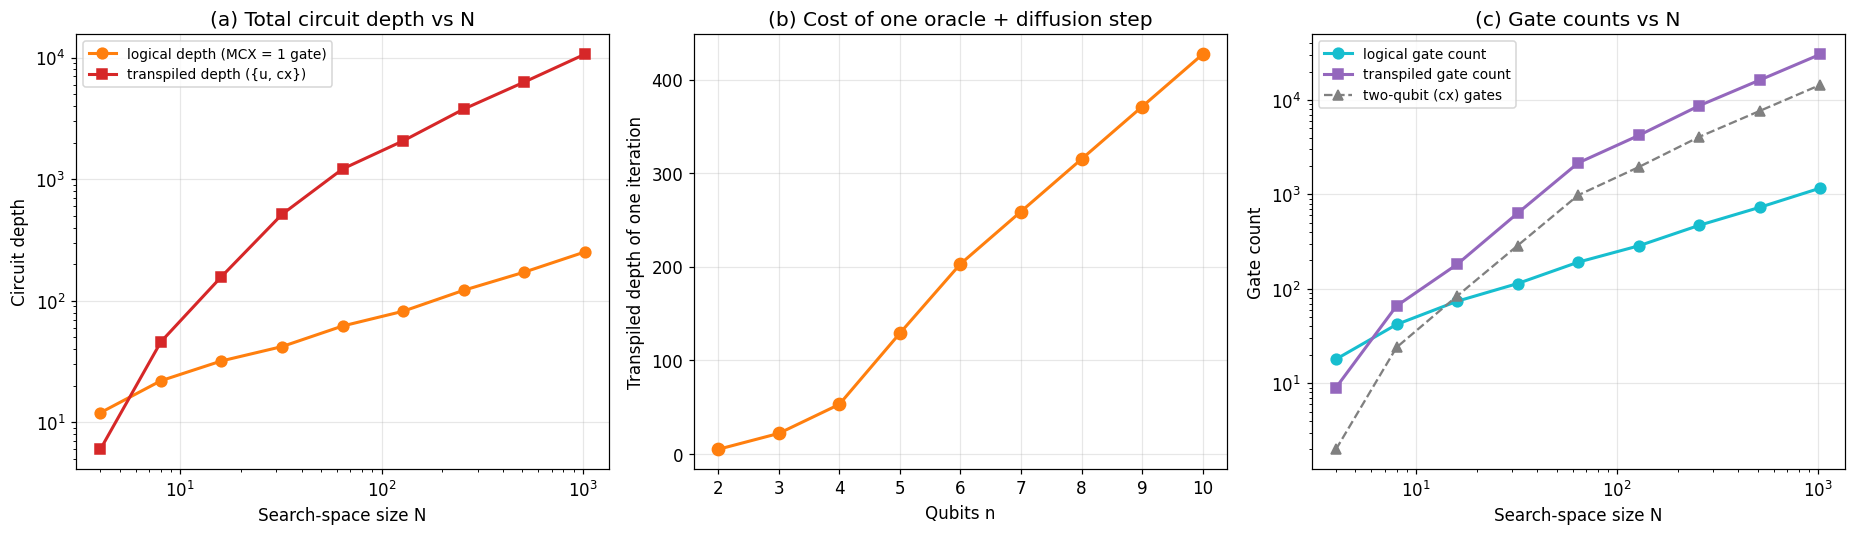

Fitted exponent  depth ~ N^a :  logical a = 0.522   transpiled a = 1.260
Transpiled depth per iteration for n >= 6 is linear in n: depth ≈ 56.0·n -133.0   (max residual 0.00)


N,n_qubits,k,logical_depth,logical_gates,transpiled_depth,transpiled_gates,cx_gates,depth / iteration
4,2,1,12,18,6,9,2,5
8,3,2,22,42,46,66,24,22
16,4,3,32,74,158,182,84,53
32,5,4,42,114,514,634,288,129
64,6,6,62,192,1214,2160,984,203
128,7,8,82,286,2066,4222,1952,259
256,8,12,122,472,3770,8728,4080,315
512,9,17,172,732,6292,16304,7684,371
1024,10,25,252,1170,10652,30570,14500,427


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) depth vs N
ax = axes[0]
ax.loglog(sweep["N"], sweep["logical_depth"], "o-", color=C_DEPTH, lw=2, ms=7, label="logical depth (MCX = 1 gate)")
ax.loglog(sweep["N"], sweep["transpiled_depth"], "s-", color=C_CLASSICAL, lw=2, ms=7, label="transpiled depth ({u, cx})")
ax.set_xlabel("Search-space size N"); ax.set_ylabel("Circuit depth")
ax.set_title("(a) Total circuit depth vs N"); ax.legend(loc="upper left", fontsize=9)

# (b) depth of ONE Grover iteration vs n
ax = axes[1]
ax.plot(sweep["n_qubits"], sweep["depth_per_iteration"], "o-", color=C_DEPTH, lw=2, ms=8)
ax.set_xlabel("Qubits n"); ax.set_ylabel("Transpiled depth of one iteration")
ax.set_title("(b) Cost of one oracle + diffusion step")

# (c) gate counts vs N
ax = axes[2]
ax.loglog(sweep["N"], sweep["logical_gates"], "o-", color=C_GATES, lw=2, ms=7, label="logical gate count")
ax.loglog(sweep["N"], sweep["transpiled_gates"], "s-", color=C_QUBITS, lw=2, ms=7, label="transpiled gate count")
ax.loglog(sweep["N"], sweep["cx_gates"], "^--", color="gray", lw=1.5, ms=6, label="two-qubit (cx) gates")
ax.set_xlabel("Search-space size N"); ax.set_ylabel("Gate count")
ax.set_title("(c) Gate counts vs N"); ax.legend(loc="upper left", fontsize=9)
finish(fig, "circuit_complexity.png")

# scaling exponents and the per-iteration trend
lg = np.log(sweep["N"])
exp_logical = np.polyfit(lg, np.log(sweep["logical_depth"]), 1)[0]
exp_trans   = np.polyfit(lg, np.log(sweep["transpiled_depth"]), 1)[0]
big = sweep[sweep["n_qubits"] >= 6]
per_qubit = np.polyfit(big["n_qubits"], big["depth_per_iteration"], 1)
resid = np.abs(np.polyval(per_qubit, big["n_qubits"]) - big["depth_per_iteration"]).max()
print(f"Fitted exponent  depth ~ N^a :  logical a = {exp_logical:.3f}   transpiled a = {exp_trans:.3f}")
print(f"Transpiled depth per iteration for n >= 6 is linear in n: "
      f"depth ≈ {per_qubit[0]:.1f}·n {per_qubit[1]:+.1f}   (max residual {resid:.2f})")

display(sweep[["N", "n_qubits", "grover_queries", "logical_depth", "logical_gates",
               "transpiled_depth", "transpiled_gates", "cx_gates", "depth_per_iteration"]]
        .rename(columns={"grover_queries": "k", "depth_per_iteration": "depth / iteration"})
        .style.hide(axis="index"))

In [30]:
# 8.5 Summary for the required sizes

req = sweep[sweep["N"].isin([4, 8, 16, 32])]
summary = pd.DataFrame({
    "N": req["N"],
    "qubits": req["n_qubits"],
    "classical queries (worst / avg)": [f"{int(a)} / {b:g}" for a, b in zip(req["classical_worst"], req["classical_avg"])],
    "Grover queries k": req["grover_queries"],
    "P(success), exact": req["p_exact"].round(4),
    "P(success), Aer": req["p_aer"].round(4),
    "logical depth": req["logical_depth"],
    "transpiled depth": req["transpiled_depth"],
    "cx gates": req["cx_gates"],
}).set_index("N")
display(summary)

,qubits,classical queries (worst / avg),Grover queries k,"P(success), exact","P(success), Aer",logical depth,transpiled depth,cx gates
N,,,,,,,,
4,2,4 / 2.5,1,1.0000,1.0000,12,6,2
8,3,8 / 4.5,2,0.9453,0.9424,22,46,24
16,4,16 / 8.5,3,0.9613,0.9600,32,158,84
32,5,32 / 16.5,4,0.9992,0.9990,42,514,288
